# Vaso-reward positive control & confounding-by-indication sensitivity analysis

The health-score CQL policy recommends ~zero vaso everywhere. These runs add a per-step reward
`c * vis_{t+1} / max(vis)` (= `c * a_vaso` on train) at timesteps where the clinician gave vaso,
with `c = vaso_reward_coefficient`.

Two questions:
1. **Positive control** – can the architecture/training produce vaso dosing at all, and does it learn *when* (tracks clinician indication) rather than firing everywhere?
2. **Sensitivity analysis** – how large must the added benefit be before the critic stops penalising vaso where clinicians gave it (tipping point `c*`, in health-score points / hour / unit normalised VIS)? If the c=0 penalty is due to confounding by indication, `c*` is the magnitude of that bias.

All analysis on **VAL** (consistent with the alpha sweep – nothing here touches test).

In [1]:
import sys
import os
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.rl.evaluate_cql_alpha_sweep as eval_cql
import src.rl.evaluate_terminal_reward_models as etm
import src.rl.evaluate_vaso_reward_sweep as vrs
import src.rl.action_distribution_sweep as action_dist
import src.rl.dose_histogram_by_alpha as dose_hist
import src.rl.clinician_baseline as clin_baseline

KeyboardInterrupt: 

# paths

In [29]:
basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only"
dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/single_seed"
cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only"

vaso_sweep_dir = os.path.join(cql_model_dir, "vaso_reward_coefficient_sweep")

# bonus-free c=0 reference. Set to the folder holding the final fixed-alpha seeds
# (must use the SAME cql_alpha as the sweep), or None if the sweep already includes c=0.
baseline_dir = os.path.join(cql_model_dir, "cql_alpha_sweep")  # find the run with cql_alpha == same as vaso_sweep models

SAVE_DIR = os.path.join(vaso_sweep_dir, "analysis")
os.makedirs(SAVE_DIR, exist_ok=True)

# state dim

In [22]:
dynamic_deephit_dir = eval_cql.get_model_dirs(dynamic_deephit_model_dir)[0]
with open(os.path.join(dynamic_deephit_dir, "results.json"), "r") as f:
    dynamic_deephit_results = json.load(f)
state_dim = dynamic_deephit_results['hyperparameters']['d_model']
print(f"state_dim = {state_dim}")

Found model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/single_seed/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_4_20260821_202242_593682_job3875805.pbs-7/unknown_cx3-20-1_20260821-202508_49e52257
state_dim = 128


# Load SARSA models x 5 seeds (bonus-free, independent judges)

In [23]:
basic_q_health_score_model_dirs = etm.get_model_dirs(basic_q_dir)
basic_q_health_score_models = []
for model_dir in basic_q_health_score_model_dirs:
    critic, cm, hp = etm.load_sarsa_critic(reward_type='health_score', model_dir=model_dir, state_dim=state_dim)
    basic_q_health_score_models.append((critic, cm, hp))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-172402_1ce5be77
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-165737_72aa451a
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-174709_9876cf65
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_mod

# Load vaso-reward sweep models
Grouped by `vaso_reward_coefficient`, cross-checked against each run's own `final_model.pt` (not `config_manager.pkl`).

In [37]:
models_by_coef, model_table = vrs.load_vaso_sweep_models(
    vaso_sweep_dir, state_dim, baseline_dir=None, verify_checkpoints=True,
)
# cql_alpha and seed shared by every run in the vaso sweep
sweep_alphas = model_table["cql_alpha"].dropna().unique()
sweep_seeds = model_table["seed"].dropna().unique()
assert len(sweep_alphas) == 1, f"vaso sweep runs use multiple cql_alpha values: {sweep_alphas}"
target_alpha = float(sweep_alphas[0])
target_seed = sweep_seeds[0] if len(sweep_seeds) == 1 else None
print(f"vaso sweep: cql_alpha={target_alpha}, seed(s)={sweep_seeds}")

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_reward_coefficient_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260929_173033/unknown_cx3-20-0_20260929-192442_9a084f90
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_reward_coefficient_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260929_173033/unknown_cx3-20-0_20260929-182751_ed630447
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/vaso_reward_coefficient_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparame

In [38]:
# --- find the bonus-free run in the alpha sweep with the same cql_alpha ---
baseline_dir = os.path.join(cql_model_dir, "cql_alpha_sweep")

matches = []
for d in eval_cql.get_model_dirs(baseline_dir):
    ck_hp = vrs._checkpoint_hyperparams(d)          # checkpoint = source of truth
    if ck_hp is None or ck_hp.get("cql_alpha") is None:
        print(f"  skipping (no checkpoint hyperparams): {d}")
        continue
    if np.isclose(ck_hp["cql_alpha"], target_alpha, rtol=1e-6, atol=1e-9):
        matches.append((d, ck_hp))

assert len(matches) == 1, f"expected exactly 1 alpha-sweep run at cql_alpha={target_alpha}, found {len(matches)}: {[m[0] for m in matches]}"
baseline_model_dir, baseline_ck_hp = matches[0]

assert not baseline_ck_hp.get("add_reward_to_vaso_dosing", False), "baseline run has the vaso bonus switched on"
if target_seed is not None and baseline_ck_hp.get("seed") != target_seed:
    print(f"WARNING: baseline seed {baseline_ck_hp.get('seed')} != vaso sweep seed {target_seed}")

actor, critic, cm, hp = etm.load_actor_and_critic(model_dir=baseline_model_dir, model_type="cql", state_dim=state_dim)
print(f"baseline: {baseline_model_dir}\n  cql_alpha={hp.get('cql_alpha')}, seed={hp.get('seed')}")

if 0.0 in models_by_coef:
    print("NOTE: vaso sweep already has a c=0 run; baseline added as an extra c=0 entry.")
models_by_coef.setdefault(0.0, []).append((actor, critic, cm, hp))
models_by_coef = dict(sorted(models_by_coef.items()))
print("coefficients:", list(models_by_coef.keys()))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260912_123321/unknown_cx3-20-3_20260912-133953_81adcdb0
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260912_123321/unknown_cx3-20-3_20260912-123448_82624754
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/with_actions/health_score_change_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260912_123321/unknown_cx3-20-3

# Load data (bonus switched off – rewards aren't used below, but keeps processors clean)

In [40]:
_, _, data_config_manager, data_hyperparams = next(iter(models_by_coef.values()))[0]
data_hyperparams = dict(data_hyperparams)
data_hyperparams['add_reward_to_vaso_dosing'] = False

data_config_manager.data_config['unit_stay_ids_path'] = os.path.join(
    data_config_manager.get_data_dir, 'cohorts', 'icu_units', f"{data_config_manager.unit.lower()}_stay_ids.csv")
data_config_manager.data_config['age_stay_ids_path'] = os.path.join(
    data_config_manager.get_data_dir, 'cohorts', 'age', 'pediatric_stay_ids.csv')

# have recently introduced a seed_mode attribute to config_manager, but older runs may not have it. Default to single_seed if not present.
if not hasattr(data_config_manager, "seed_mode"):
    data_config_manager.seed_mode = "single_seed"

processors = {}
processors['train'], processors['val'], processors['test'] = etm.load_data(data_config_manager, data_hyperparams)

using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type


In [41]:
train_hs, train_dhs = vrs.per_state_health_score(processors['train'])
val_hs, val_dhs = vrs.per_state_health_score(processors['val'])
training_actions = processors['train'].rl_dataset["actions"]

sev_edges = vrs.severity_edges_from_train(train_hs, n_bins=10)   # deciles, D1 = sickest

clin_ref_val = vrs.clinician_reference(processors['val'], val_hs, sev_edges)
clin_baseline.print_clinician_baseline(clin_baseline.compute_clinician_baseline(processors['val'].rl_dataset["actions"]), label="val")

=== Clinician baseline (val) ===
  fluid: rate=90.9%, mean=0.4958, nonzero_mean=0.5456
  vaso: rate=8.3%, mean=0.0213, nonzero_mean=0.2569


# 1. Data-level evidence for confounding by indication (no models)
If vaso is started in patients who are *already deteriorating*, the next-hour health-score change credited to the
vaso action is negative even at matched current severity – which is exactly what a critic learns as "vaso is bad".

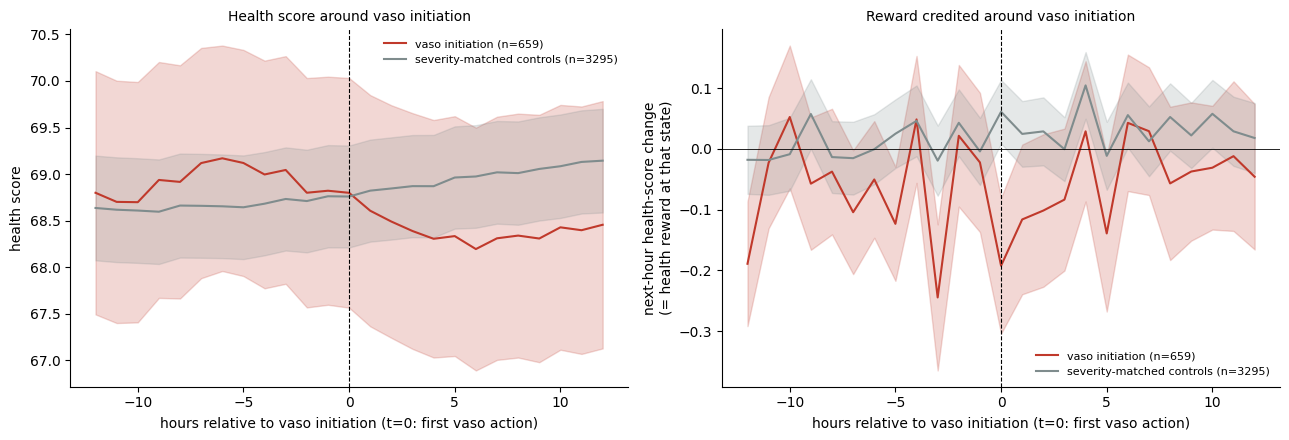

In [42]:
onset = vrs.vaso_onset_aligned(processors['train'], train_hs, train_dhs, sev_edges, pre=12, post=12, washout=6)
fig = vrs.plot_vaso_onset(onset, save_path=os.path.join(SAVE_DIR, "vaso_onset_aligned_health_score_train.png"))

,severity_bin,n_vaso,n_zero,dhs_vaso,dhs_zero,gap,gap_sem
0,0,11900,30451,0.008688,0.095261,-0.086573,0.030575
1,1,9503,32848,-0.014706,0.006032,-0.020738,0.010443
2,2,5546,36804,0.023456,0.059174,-0.035718,0.012177
3,3,3185,39166,0.034923,0.062524,-0.027601,0.018169
4,4,2407,39943,0.009791,0.065037,-0.055246,0.020708
5,5,1550,40801,0.043446,0.041456,0.001990,0.023171
6,6,1117,41233,0.040988,0.025709,0.015279,0.024756
7,7,1096,41255,0.023909,-0.000113,0.024022,0.021153
8,8,792,41559,-0.015888,-0.033752,0.017864,0.022342
9,9,759,41592,-0.030779,-0.051526,0.020748,0.014880


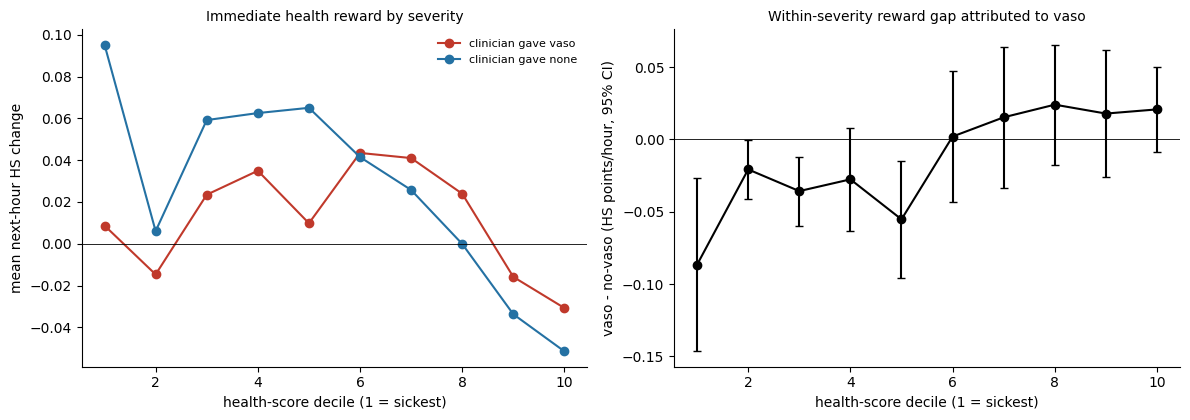

In [43]:
gap_df = vrs.reward_gap_by_severity(processors['train'], train_hs, train_dhs, sev_edges)
display(gap_df)
fig = vrs.plot_reward_gap_by_severity(gap_df, save_path=os.path.join(SAVE_DIR, "reward_gap_by_severity_train.png"))

# 2. Bonus-free SARSA reference
Same critic measures on the 5 SARSA critics (no bonus, no conservatism). Negative ⇒ the zero-vaso preference is in the
data's (s, a, r) relationship, not a CQL artefact.

In [44]:
sarsa_ref = vrs.sarsa_vaso_reference(processors['val'], basic_q_health_score_models)
for k, s in enumerate(sarsa_ref):
    print(f"SARSA seed {k+1}: dQ/unit dose = {s['dq_vaso_per_unit_dose']:+.3f} HS pts, "
          f"frac states dQ>0 = {s['dq_vaso_frac_positive']*100:.1f}%")

clin_vaso_idx = np.where(np.asarray(processors['val'].rl_dataset['actions'][:, 1]) > vrs.VASO_THRESHOLD)[0]
sarsa_sev = vrs.severity_bin(val_hs[clin_vaso_idx], sev_edges)

SARSA seed 1: dQ/unit dose = -1.313 HS pts, frac states dQ>0 = 2.6%
SARSA seed 2: dQ/unit dose = -1.453 HS pts, frac states dQ>0 = 3.8%
SARSA seed 3: dQ/unit dose = -1.189 HS pts, frac states dQ>0 = 2.6%
SARSA seed 4: dQ/unit dose = -1.391 HS pts, frac states dQ>0 = 2.8%
SARSA seed 5: dQ/unit dose = -1.151 HS pts, frac states dQ>0 = 4.1%


# 3. Run the sweep analysis (all coefficients × seeds)

In [45]:
results = vrs.run_vaso_reward_sweep_analysis(
    models_by_coef, processors['val'], basic_q_health_score_models,
    val_hs, sev_edges, training_actions, train_hs,
    n_severity_bins_occ=200,
)

=== vaso_reward_coefficient=0.0, seed=42 ===
    own-critic Q IQR (real clinician actions): 2.4042
    SARSA seed 1 Q IQR (real clinician actions): 0.9660
    SARSA seed 2 Q IQR (real clinician actions): 0.9962
    SARSA seed 3 Q IQR (real clinician actions): 0.9462
    SARSA seed 4 Q IQR (real clinician actions): 1.0221
    SARSA seed 5 Q IQR (real clinician actions): 1.0000
  vaso fire: 0.0% overall, 0.0% @clin-vaso, 0.0% @clin-zero | gate AUROC 0.426 | dQ/unit dose -0.181 HS pts | (8s)
=== vaso_reward_coefficient=0.01, seed=42 ===
    own-critic Q IQR (real clinician actions): 2.4120
    SARSA seed 1 Q IQR (real clinician actions): 0.9660
    SARSA seed 2 Q IQR (real clinician actions): 0.9962
    SARSA seed 3 Q IQR (real clinician actions): 0.9462
    SARSA seed 4 Q IQR (real clinician actions): 1.0221
    SARSA seed 5 Q IQR (real clinician actions): 1.0000
  vaso fire: 0.0% overall, 0.0% @clin-vaso, 0.0% @clin-zero | gate AUROC 0.620 | dQ/unit dose -0.134 HS pts | (7s)
=== vaso_re

In [46]:
summary = vrs.results_to_dataframe(results)
summary.to_csv(os.path.join(SAVE_DIR, "vaso_sweep_summary_val.csv"))
summary.xs("mean", axis=1, level=1)

,vaso_fire_rate,vaso_fire_rate_at_clin_vaso,vaso_fire_rate_at_clin_zero,vaso_gate_p_mean,vaso_gate_p_at_clin_vaso,vaso_gate_p_at_clin_zero,vaso_gate_auroc,vaso_dose_mean,vaso_dose_mean_when_fired,vaso_magnitude_mean,vaso_dose_spearman_cofired,fluid_fire_rate,fluid_dose_mean,dq_vaso_mean,dq_vaso_per_unit_dose,dq_vaso_frac_positive,sarsa_adv_norm,own_adv_norm,occupancy_support_frac
coef,,,,,,,,,,,,,,,,,,,
0.00,0.000000,0.000000,0.000000,0.016854,0.015580,0.016970,0.425612,0.000000,NaN,0.000003,NaN,0.996417,0.435902,-0.046614,-0.181482,0.554650,0.039125,0.004764,0.979568
0.01,0.000000,0.000000,0.000000,0.012808,0.014470,0.012657,0.620112,0.000000,NaN,0.000003,NaN,0.997049,0.464875,-0.034352,-0.133740,0.574559,0.037984,0.004394,0.976828
0.05,0.000000,0.000000,0.000000,0.021702,0.023707,0.021520,0.558034,0.000000,NaN,0.000004,NaN,0.998381,0.516180,-0.008034,-0.031279,0.644842,0.032267,0.002900,0.962630
0.10,0.000000,0.000000,0.000000,0.013441,0.018914,0.012946,0.666784,0.000000,NaN,0.000028,NaN,0.996473,0.425475,-0.000299,-0.001165,0.687333,0.042312,0.003059,0.977183
0.20,0.000000,0.000000,0.000000,0.027592,0.043424,0.026159,0.800457,0.000000,NaN,0.000287,NaN,0.997815,0.526065,0.024675,0.096066,0.722207,0.030139,0.001595,0.967144
0.25,0.273183,0.806654,0.224888,0.275514,0.803417,0.227722,0.872243,0.041027,0.150181,0.041459,0.301566,1.000000,0.507419,-0.027398,-0.106666,0.542758,-0.012119,0.006579,0.896552
0.30,0.266028,0.819882,0.215888,0.268537,0.817507,0.218838,0.881366,0.044516,0.167337,0.044806,0.232469,1.000000,0.547057,-0.025383,-0.098823,0.533805,-0.018986,0.006703,0.876653
0.35,0.298562,0.842998,0.249274,0.301749,0.842532,0.252792,0.881419,0.051519,0.172557,0.051837,0.355002,0.999368,0.512669,-0.014880,-0.057930,0.581507,-0.025232,0.007144,0.886470
0.40,0.280881,0.821753,0.231916,0.282431,0.823161,0.233478,0.883787,0.053360,0.189974,0.054001,0.310979,0.999756,0.514890,-0.023831,-0.092782,0.544228,-0.024683,0.007150,0.888255


In [55]:
dups = model_table[model_table.duplicated(subset="dir", keep=False)]
print("duplicate directories:\n", dups if len(dups) else "none")
print(model_table.groupby("coef").size())

duplicate directories:
 none
coef
0.01     1
0.05     1
0.10     1
0.20     1
0.25     1
0.30     1
0.35     1
0.40     1
0.45     1
0.50     2
1.00     1
2.50     1
5.00     1
10.00    1
20.00    1
dtype: int64


# 4. Policy vaso dosing vs. coefficient
Read panel (c) alongside (a): a successful positive control should raise fire rate at clinician-vaso states much faster
than at clinician-zero states, with AUROC well above 0.5. Panel (e) checks the bonus didn't distort fluid; panel (f)
is the cost on the original, bonus-free objective. *Own-critic advantage is not comparable across c (different reward) – not plotted.*

/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_vaso_reward_sweep.py:461: RuntimeWarning: Mean of empty slice
  return (np.array(coefs), np.array([np.nanmean(v) for v in vals]),
/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_vaso_reward_sweep.py:462: RuntimeWarning: All-NaN slice encountered
  np.array([np.nanmin(v) for v in vals]), np.array([np.nanmax(v) for v in vals]), vals)


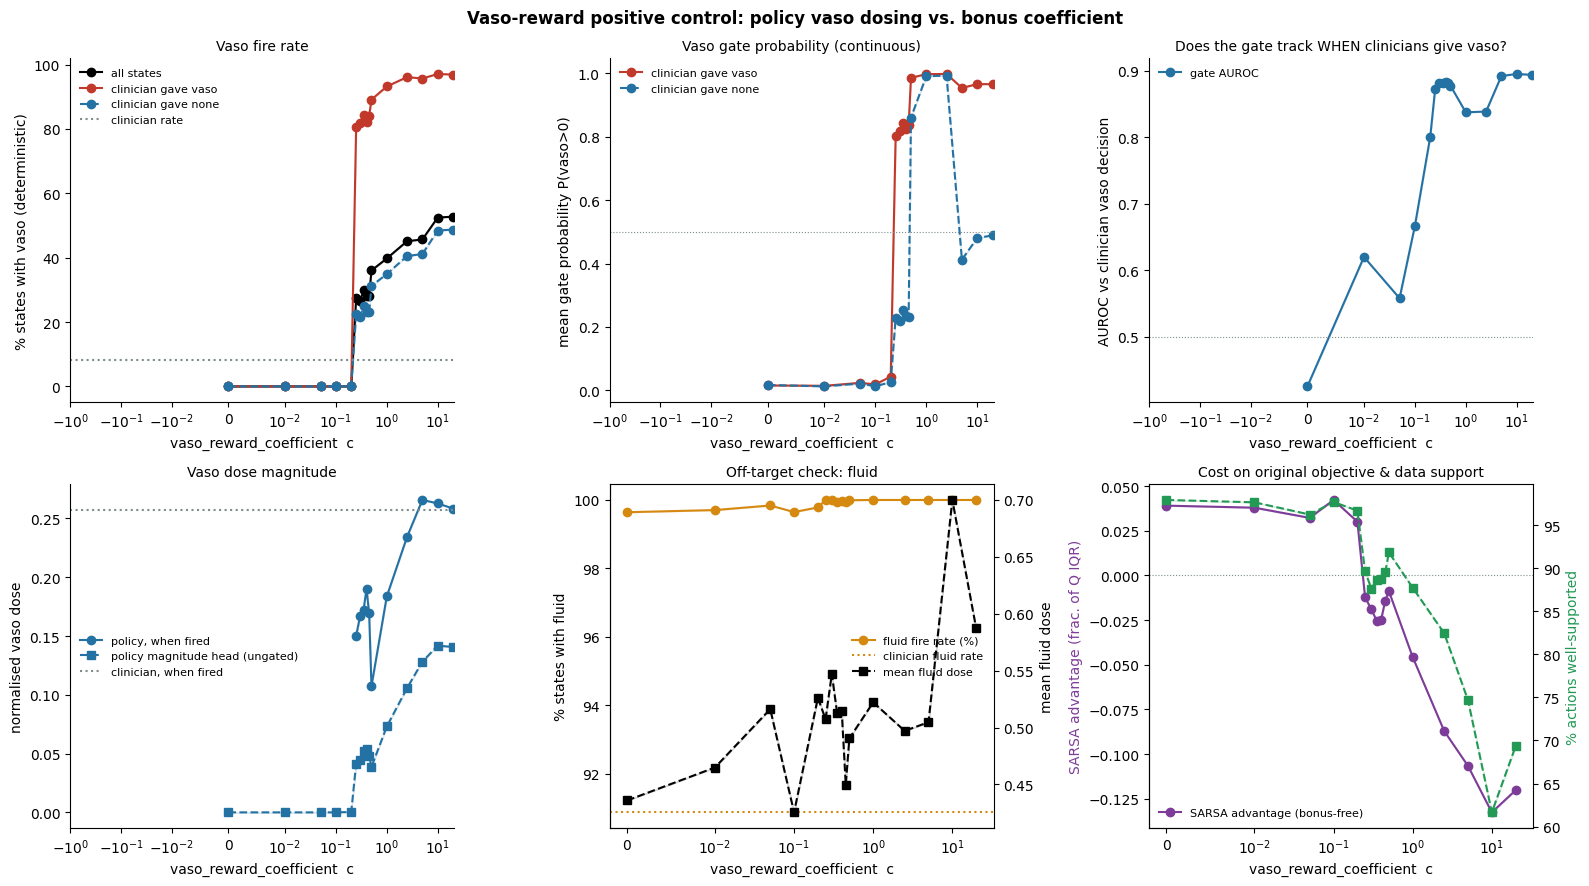

In [47]:
fig = vrs.plot_vaso_dosing_vs_coef(results, clin_ref_val,
                                   save_path=os.path.join(SAVE_DIR, "vaso_dosing_vs_coef_val.png"))

In [58]:
pd.set_option("display.float_format", "{:.4g}".format)
beh_df = vrs.behaviour_table(results, clin_ref_val)
beh_df.to_csv(os.path.join(SAVE_DIR, "behaviour_table_val.csv"))
beh_df

/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl/src/rl/evaluate_vaso_reward_sweep.py:882: RuntimeWarning: Mean of empty slice


,fire_%,fire_%_clin_vaso,fire_%_clin_zero,PPV_%,dose_when_fired,fluid_fire_%,fluid_dose_mean,n_seeds,gate_p_mean,gate_auroc,magnitude_mean,dose_spearman_cofired,sarsa_adv_norm,occupancy_%
clinician,8.302,100,0,100,0.2569,90.88,0.4958,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,0,0,0,NaN,NaN,99.64,0.4359,1,0.01685,0.4256,2.884e-06,NaN,0.03912,97.96
0.01,0,0,0,NaN,NaN,99.7,0.4649,1,0.01281,0.6201,3.474e-06,NaN,0.03798,97.68
0.05,0,0,0,NaN,NaN,99.84,0.5162,1,0.0217,0.558,3.994e-06,NaN,0.03227,96.26
0.1,0,0,0,NaN,NaN,99.65,0.4255,1,0.01344,0.6668,2.8e-05,NaN,0.04231,97.72
0.2,0,0,0,NaN,NaN,99.78,0.5261,1,0.02759,0.8005,0.0002873,NaN,0.03014,96.71
0.25,27.32,80.67,22.49,24.51,0.1502,100,0.5074,1,0.2755,0.8722,0.04146,0.3016,-0.01212,89.66
0.3,26.6,81.99,21.59,25.58,0.1673,100,0.5471,1,0.2685,0.8814,0.04481,0.2325,-0.01899,87.67
0.35,29.86,84.3,24.93,23.44,0.1726,99.94,0.5127,1,0.3017,0.8814,0.05184,0.355,-0.02523,88.65
0.4,28.09,82.18,23.19,24.29,0.19,99.98,0.5149,1,0.2824,0.8838,0.054,0.311,-0.02468,88.83


# 5. Tipping point

critic (dQ/unit dose = 0)                        c* = 0.1012   [s42:0.101]
behaviour (fires at 50% of clin-vaso states)     c* = 0.231   [s42:0.231]
rate-match (overall fire rate = clinician)       c* = 0.2152   [s42:0.215]


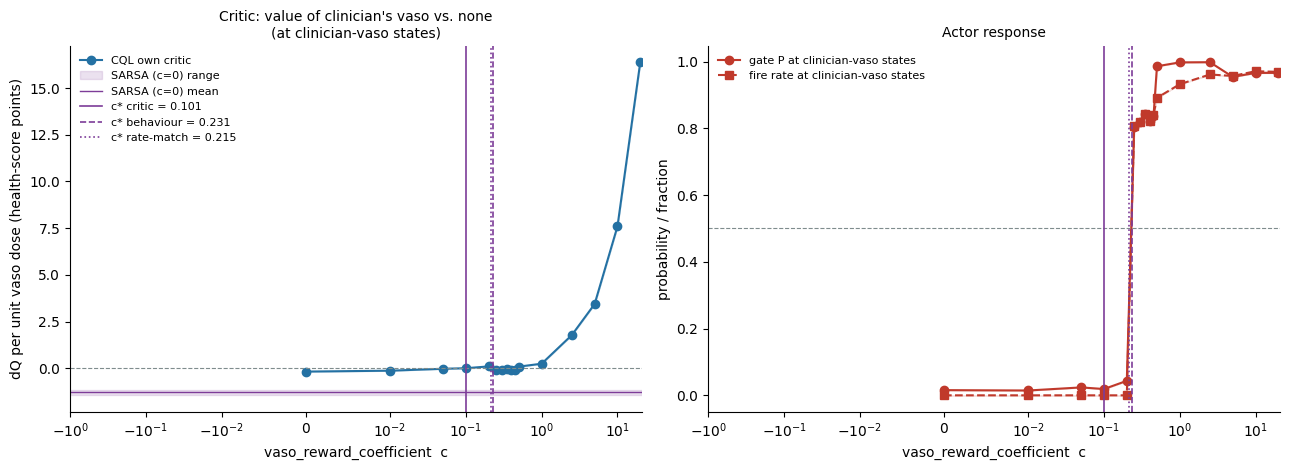

In [48]:
tipping = vrs.estimate_tipping_points(results, clin_ref_val)
fig = vrs.plot_critic_tipping_point(results, sarsa_ref, tipping,
                                    save_path=os.path.join(SAVE_DIR, "critic_tipping_point_val.png"))

In [49]:
# put the critic tipping point on interpretable scales
c_star = tipping["critic (dQ/unit dose = 0)"]["c_star"]
_ = vrs.contextualise_tipping_point(c_star, train_dhs, data_hyperparams)

  c_star (HS pts/hour per unit VIS)             0.101
  c_star / SD(hourly HS change)                 0.0836
  percentile of |hourly HS change|              13.4
  c_star / hourly clip                          0.00101
  sustained-dose value c*/(1-gamma) (HS pts)    4.05


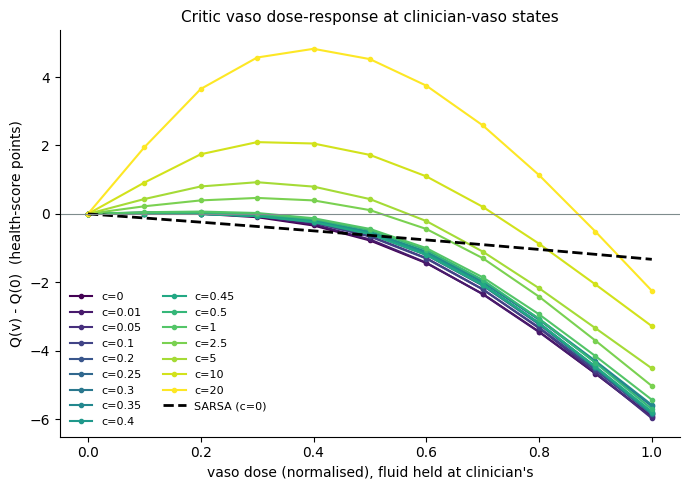

In [50]:
fig = vrs.plot_q_vaso_dose_curves(results, sarsa_ref,
                                  save_path=os.path.join(SAVE_DIR, "q_vaso_dose_curves_val.png"))

In [59]:
crit_df = vrs.critic_table(results, sarsa_ref)
crit_df.to_csv(os.path.join(SAVE_DIR, "critic_table_val.csv"))
crit_df

,dq_per_unit_dose,dq_at_clin_dose,frac_states_dq>0_%,slope_vs_prev_c
coef,,,,
0,-0.1815,-0.04661,55.46,NaN
0.01,-0.1337,-0.03435,57.46,4.774
0.05,-0.03128,-0.008034,64.48,2.562
0.1,-0.001165,-0.0002991,68.73,0.6023
0.2,0.09607,0.02467,72.22,0.9723
0.25,-0.1067,-0.0274,54.28,-4.055
0.3,-0.09882,-0.02538,53.38,0.1569
0.35,-0.05793,-0.01488,58.15,0.8179
0.4,-0.09278,-0.02383,54.42,-0.697


# 6. Severity structure
Heatmap: does emerging vaso follow the clinicians' severity gradient? Penalty plot: at c=0, a vaso penalty largest in the sickest
deciles is the pattern expected under confounding by indication.

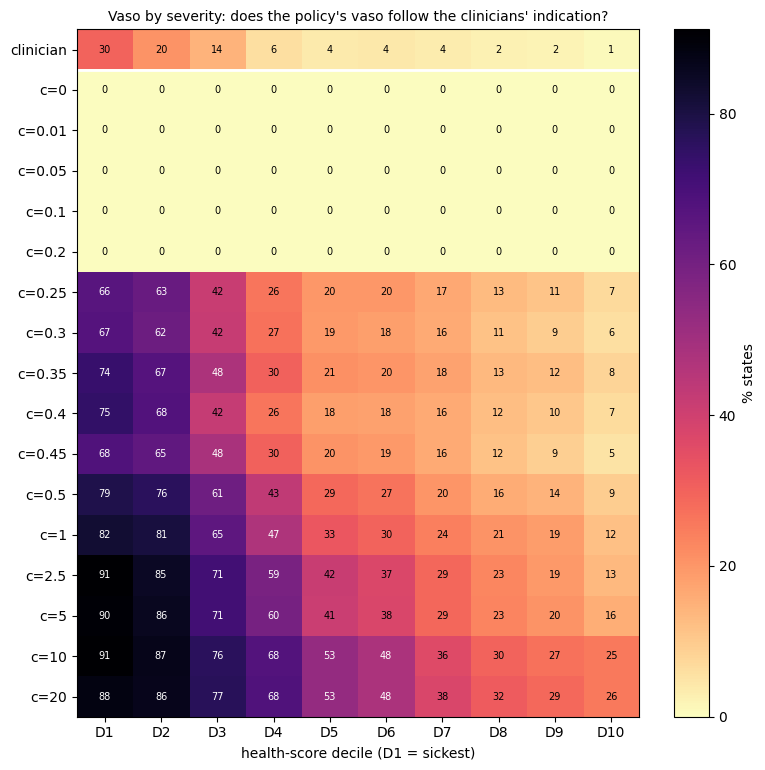

In [51]:
fig = vrs.plot_vaso_by_severity(results, clin_ref_val,
                                save_path=os.path.join(SAVE_DIR, "vaso_fire_by_severity_val.png"))

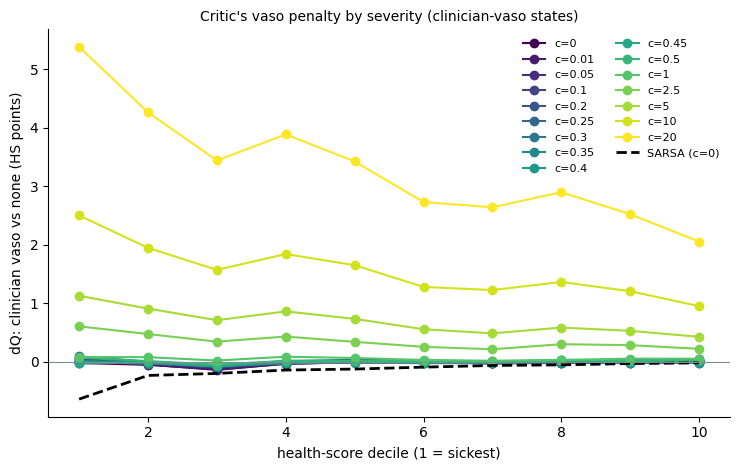

In [52]:
fig = vrs.plot_vaso_penalty_by_severity(results, sev_edges, sarsa_ref, sarsa_sev=sarsa_sev,
                                        save_path=os.path.join(SAVE_DIR, "vaso_penalty_by_severity_val.png"))

In [60]:
fire_sev_df, pen_sev_df = vrs.severity_tables(results, clin_ref_val, sev_edges, sarsa_ref, sarsa_sev)
display(fire_sev_df.round(1))
display(pen_sev_df.round(3))

,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
clinician,29.6,20.4,14.4,5.8,3.8,4.2,3.5,2.3,1.8,0.8
0,0,0,0,0,0,0,0,0,0,0
0.01,0,0,0,0,0,0,0,0,0,0
0.05,0,0,0,0,0,0,0,0,0,0
0.1,0,0,0,0,0,0,0,0,0,0
0.2,0,0,0,0,0,0,0,0,0,0
0.25,66.4,62.8,41.6,26.2,19.6,19.9,16.7,13.1,11.3,7
0.3,67,61.7,41.8,26.8,19.4,18.3,16.1,11.5,9.4,5.8
0.35,73.6,67,47.6,30.2,21.2,20.1,17.5,13.3,12.2,7.9
0.4,74.6,67.8,42.4,26.2,18.3,18.1,16.3,12.3,10.4,6.6


,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
0,-0.021,-0.053,-0.132,-0.037,-0.009,-0.005,-0.027,-0.022,-0.003,0.005
0.01,0.013,-0.047,-0.14,-0.032,-0.009,-0.015,-0.021,-0.011,0.006,0.011
0.05,0.051,-0.025,-0.107,0.001,0.004,-0.006,-0.03,-0.007,-0.014,-0.007
0.1,0.057,-0.015,-0.102,-0.02,0.017,0.006,-0.001,0.019,0.016,0.013
0.2,0.09,0,-0.068,0.007,0.033,0.02,0.007,0.021,0.026,0.039
0.25,-0.012,-0.028,-0.077,-0.016,-0.009,-0.013,-0.019,-0.014,-0.02,-0.018
0.3,-0.003,-0.031,-0.079,-0.014,-0.008,-0.021,-0.026,-0.014,-0.007,0.001
0.35,0.013,-0.012,-0.081,-0.013,-0.001,-0.012,-0.017,-0.009,-0.02,-0.017
0.4,-0.01,-0.017,-0.071,-0.027,-0.013,-0.025,-0.021,0,0,-0.001
0.45,-0.03,-0.011,-0.08,0.016,0.015,0.002,-0.004,0.021,0.013,0.021


In [61]:
actor0, critic0, _, hp0 = models_by_coef[0.0][0]
states = processors['val'].rl_dataset['states']
states_np = states.numpy() if torch.is_tensor(states) else np.asarray(states)
with torch.no_grad():
    s = torch.as_tensor(states_np[clin_vaso_idx], dtype=torch.float32, device=next(actor0.parameters()).device)
    _, _, _, (f_p, v_p, f_raw, v_raw, f_std, v_std) = actor0(s, deterministic=True, return_dist=True)
v_raw = v_raw.squeeze(-1).cpu().numpy(); v_p = v_p.squeeze(-1).cpu().numpy()
dq0 = results[0.0][0]["dq_vaso_states"]
for name, m in [("dQ>0 (critic favours vaso)", dq0 > 0), ("dQ<=0", dq0 <= 0)]:
    print(f"{name:28s} n={m.sum():5d}  v_raw_mean median={np.median(v_raw[m]):.2f}  "
          f"gate p median={np.median(v_p[m]):.4f}  mean-sat reg weight 4p(1-p)={np.mean(4*v_p[m]*(1-v_p[m])):.3f}")

dQ>0 (critic favours vaso)   n= 4151  v_raw_mean median=-12.70  gate p median=0.0168  mean-sat reg weight 4p(1-p)=0.061
dQ<=0                        n= 3333  v_raw_mean median=-12.89  gate p median=0.0166  mean-sat reg weight 4p(1-p)=0.061


# 7. Dose histograms (existing plotting functions; first seed per coefficient)

=== Vaso dose distribution summary (nonzero doses only) ===
  Clinician (real): n=7484, mean=0.2569, std=0.1127, median=0.2319, p10=0.1552, p25=0.1718, p75=0.2971, p90=0.4037
  alpha=0.0: no nonzero doses


/home/jake/miniconda3/envs/rl_env/lib/python3.10/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


  alpha=0.01: no nonzero doses
  alpha=0.05: no nonzero doses
  alpha=0.1: no nonzero doses
  alpha=0.2: no nonzero doses
  alpha=0.25: n=24628, mean=0.1502, std=0.1178, median=0.1248, p10=0.0203, p25=0.0528, p75=0.2196, p90=0.3218
  alpha=0.3: n=23983, mean=0.1673, std=0.1247, median=0.1518, p10=0.0169, p25=0.0572, p75=0.2504, p90=0.3401
  alpha=0.35: n=26916, mean=0.1726, std=0.1311, median=0.1538, p10=0.0173, p25=0.0611, p75=0.2563, p90=0.3488
  alpha=0.4: n=25322, mean=0.1900, std=0.1371, median=0.1665, p10=0.0296, p25=0.0757, p75=0.2724, p90=0.3933
  alpha=0.45: n=25285, mean=0.1693, std=0.1393, median=0.1375, p10=0.0192, p25=0.0548, p75=0.2472, p90=0.3688
  alpha=0.5: n=32473, mean=0.1074, std=0.1145, median=0.0772, p10=0.0004, p25=0.0043, p75=0.1719, p90=0.2738
  alpha=1.0: n=35843, mean=0.1837, std=0.1438, median=0.1837, p10=0.0008, p25=0.0284, p75=0.2956, p90=0.3783
  alpha=2.5: n=40676, mean=0.2343, std=0.1497, median=0.2558, p10=0.0023, p25=0.1133, p75=0.3451, p90=0.4191
  a

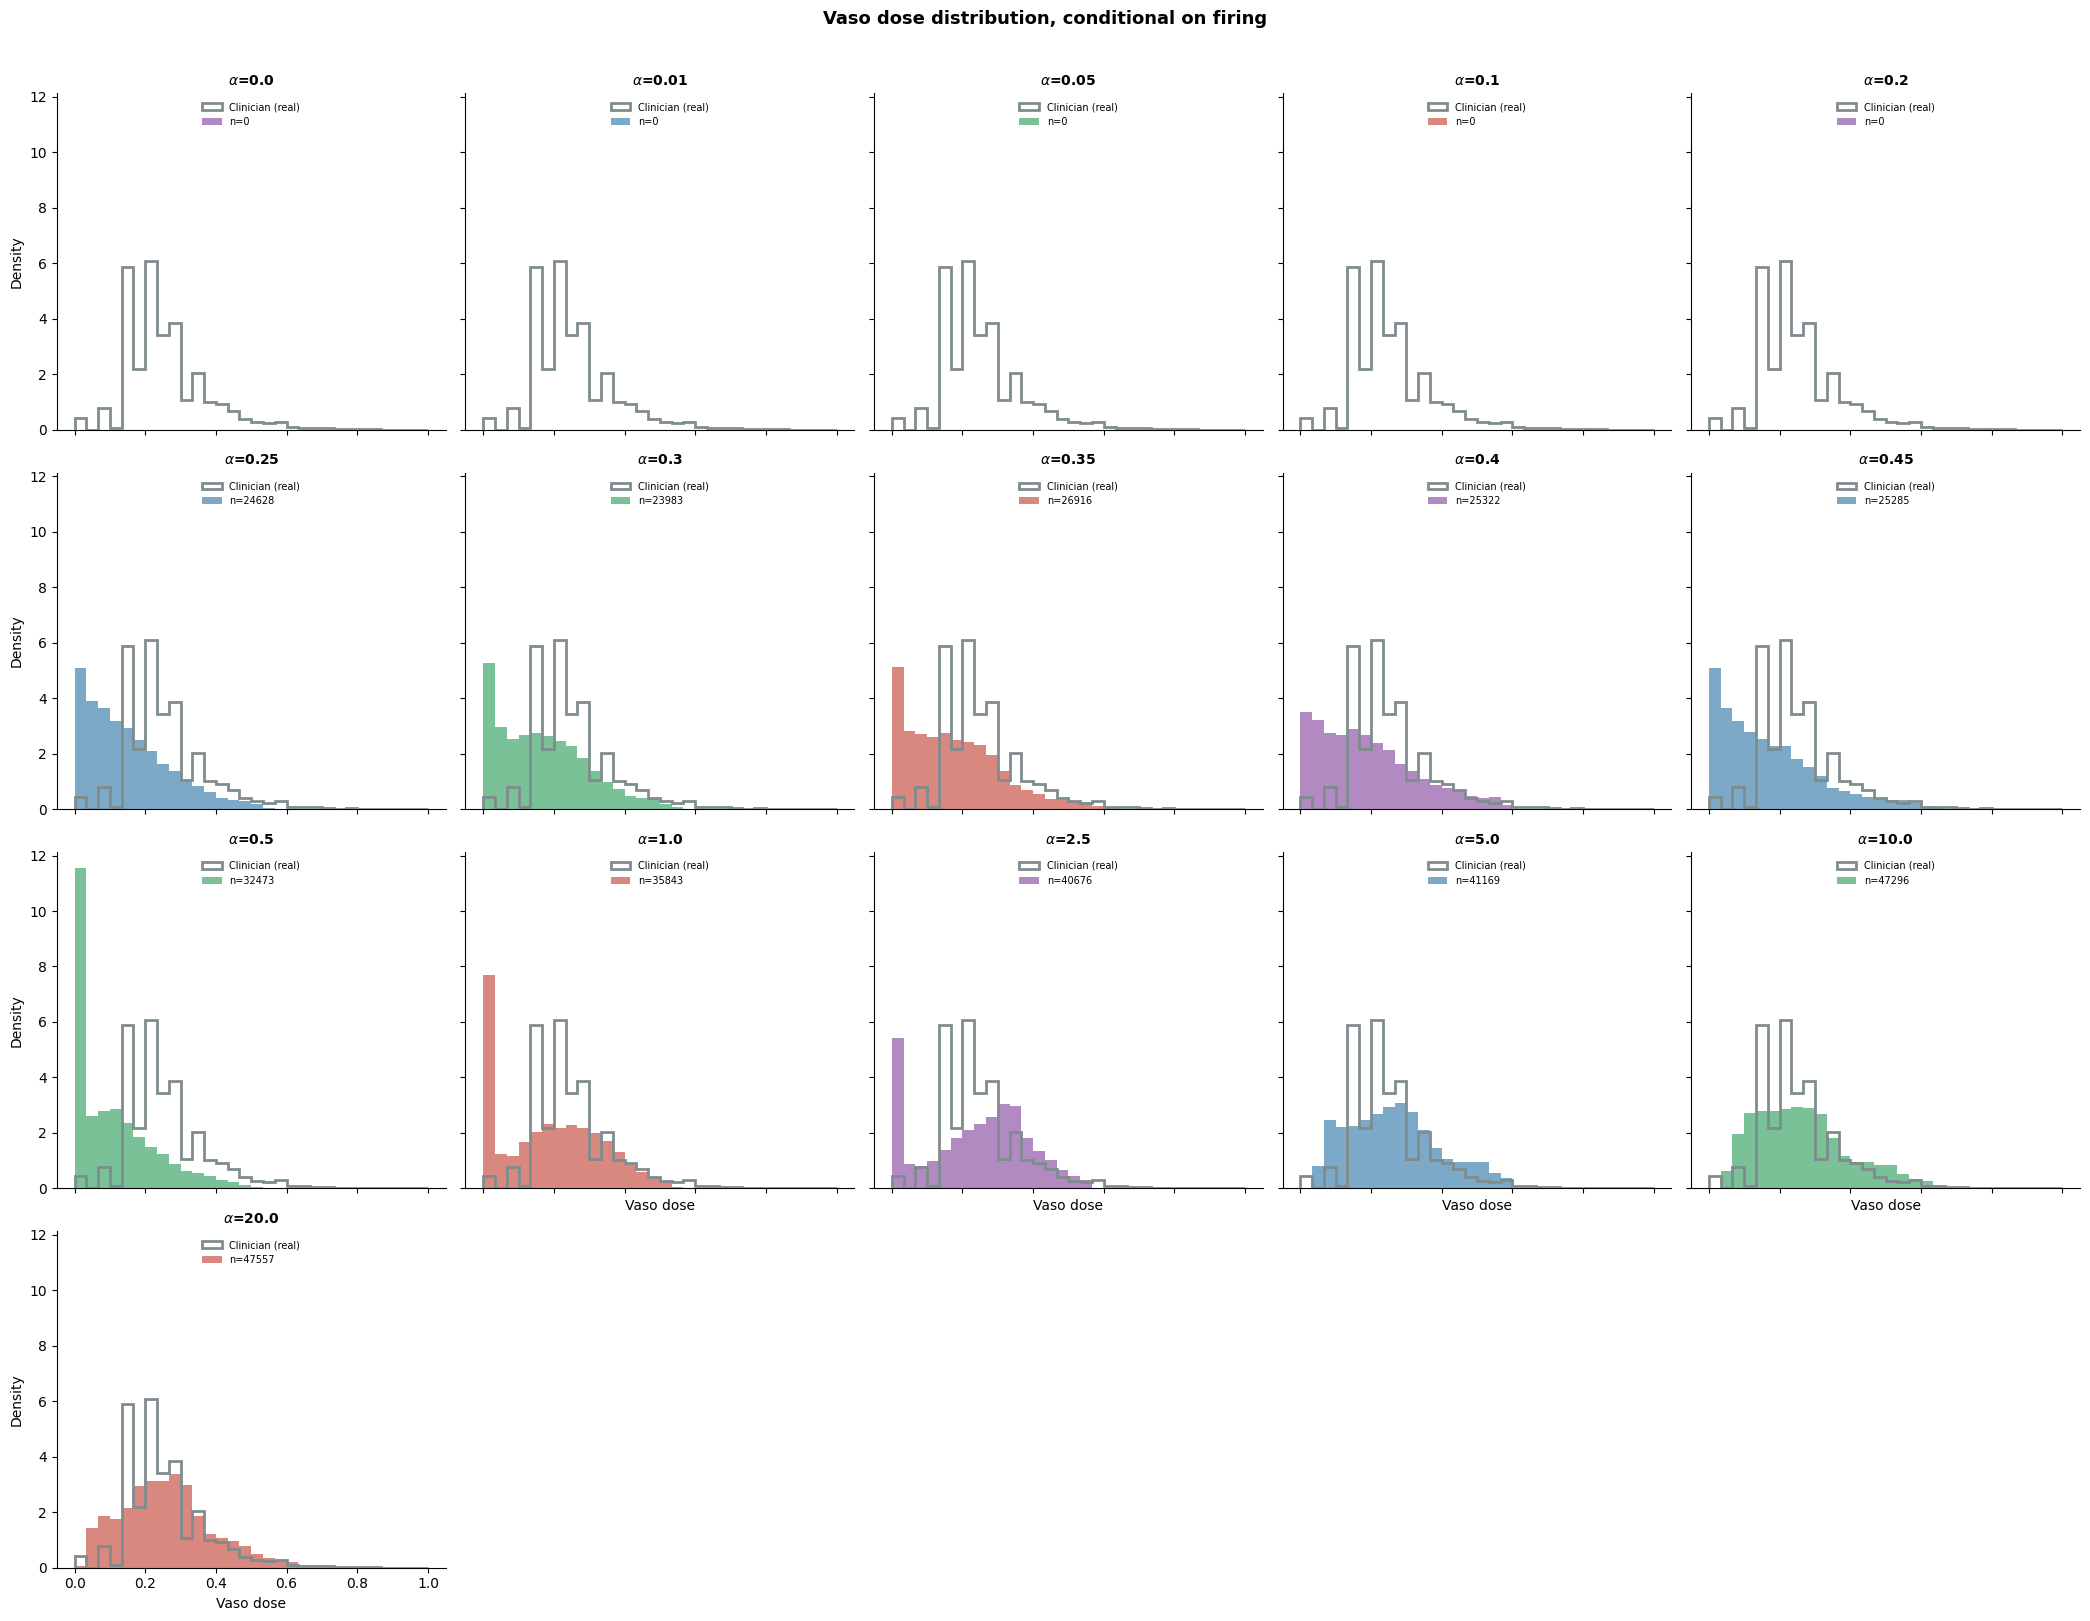

In [53]:
clinician_actions_val = processors['val'].rl_dataset["actions"]
first_seed_by_coef = {c: entries[0] for c, entries in models_by_coef.items()}

fig = dose_hist.plot_dose_histograms(
    first_seed_by_coef, processor=processors['val'], clinician_actions=clinician_actions_val,
    dim=1, dim_name="Vaso", get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(SAVE_DIR, "dose_histogram_vaso_by_coef.png"),
)

=== Vaso: model dose distribution AT clinician-zero states (n=82668, 91.7% of all states) ===
  alpha=0.0: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.01: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.05: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.1: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.2: agrees (recommends ~0) at 100.0% of clinician-zero states (no disagreements)
  alpha=0.25: agrees (recommends ~0) at 77.5% of clinician-zero states; among the 18591 disagreements, mean dose=0.1233, median=0.1004
  alpha=0.3: agrees (recommends ~0) at 78.4% of clinician-zero states; among the 17847 disagreements, mean dose=0.1386, median=0.1231
  alpha=0.35: agrees (recommends ~0) at 75.1% of clinician-zero states; among the 20607 disagreements, mean dose=0.1411, median=0.1232
  alpha=0.4: agrees (recommends ~0) at 76.8% of cl

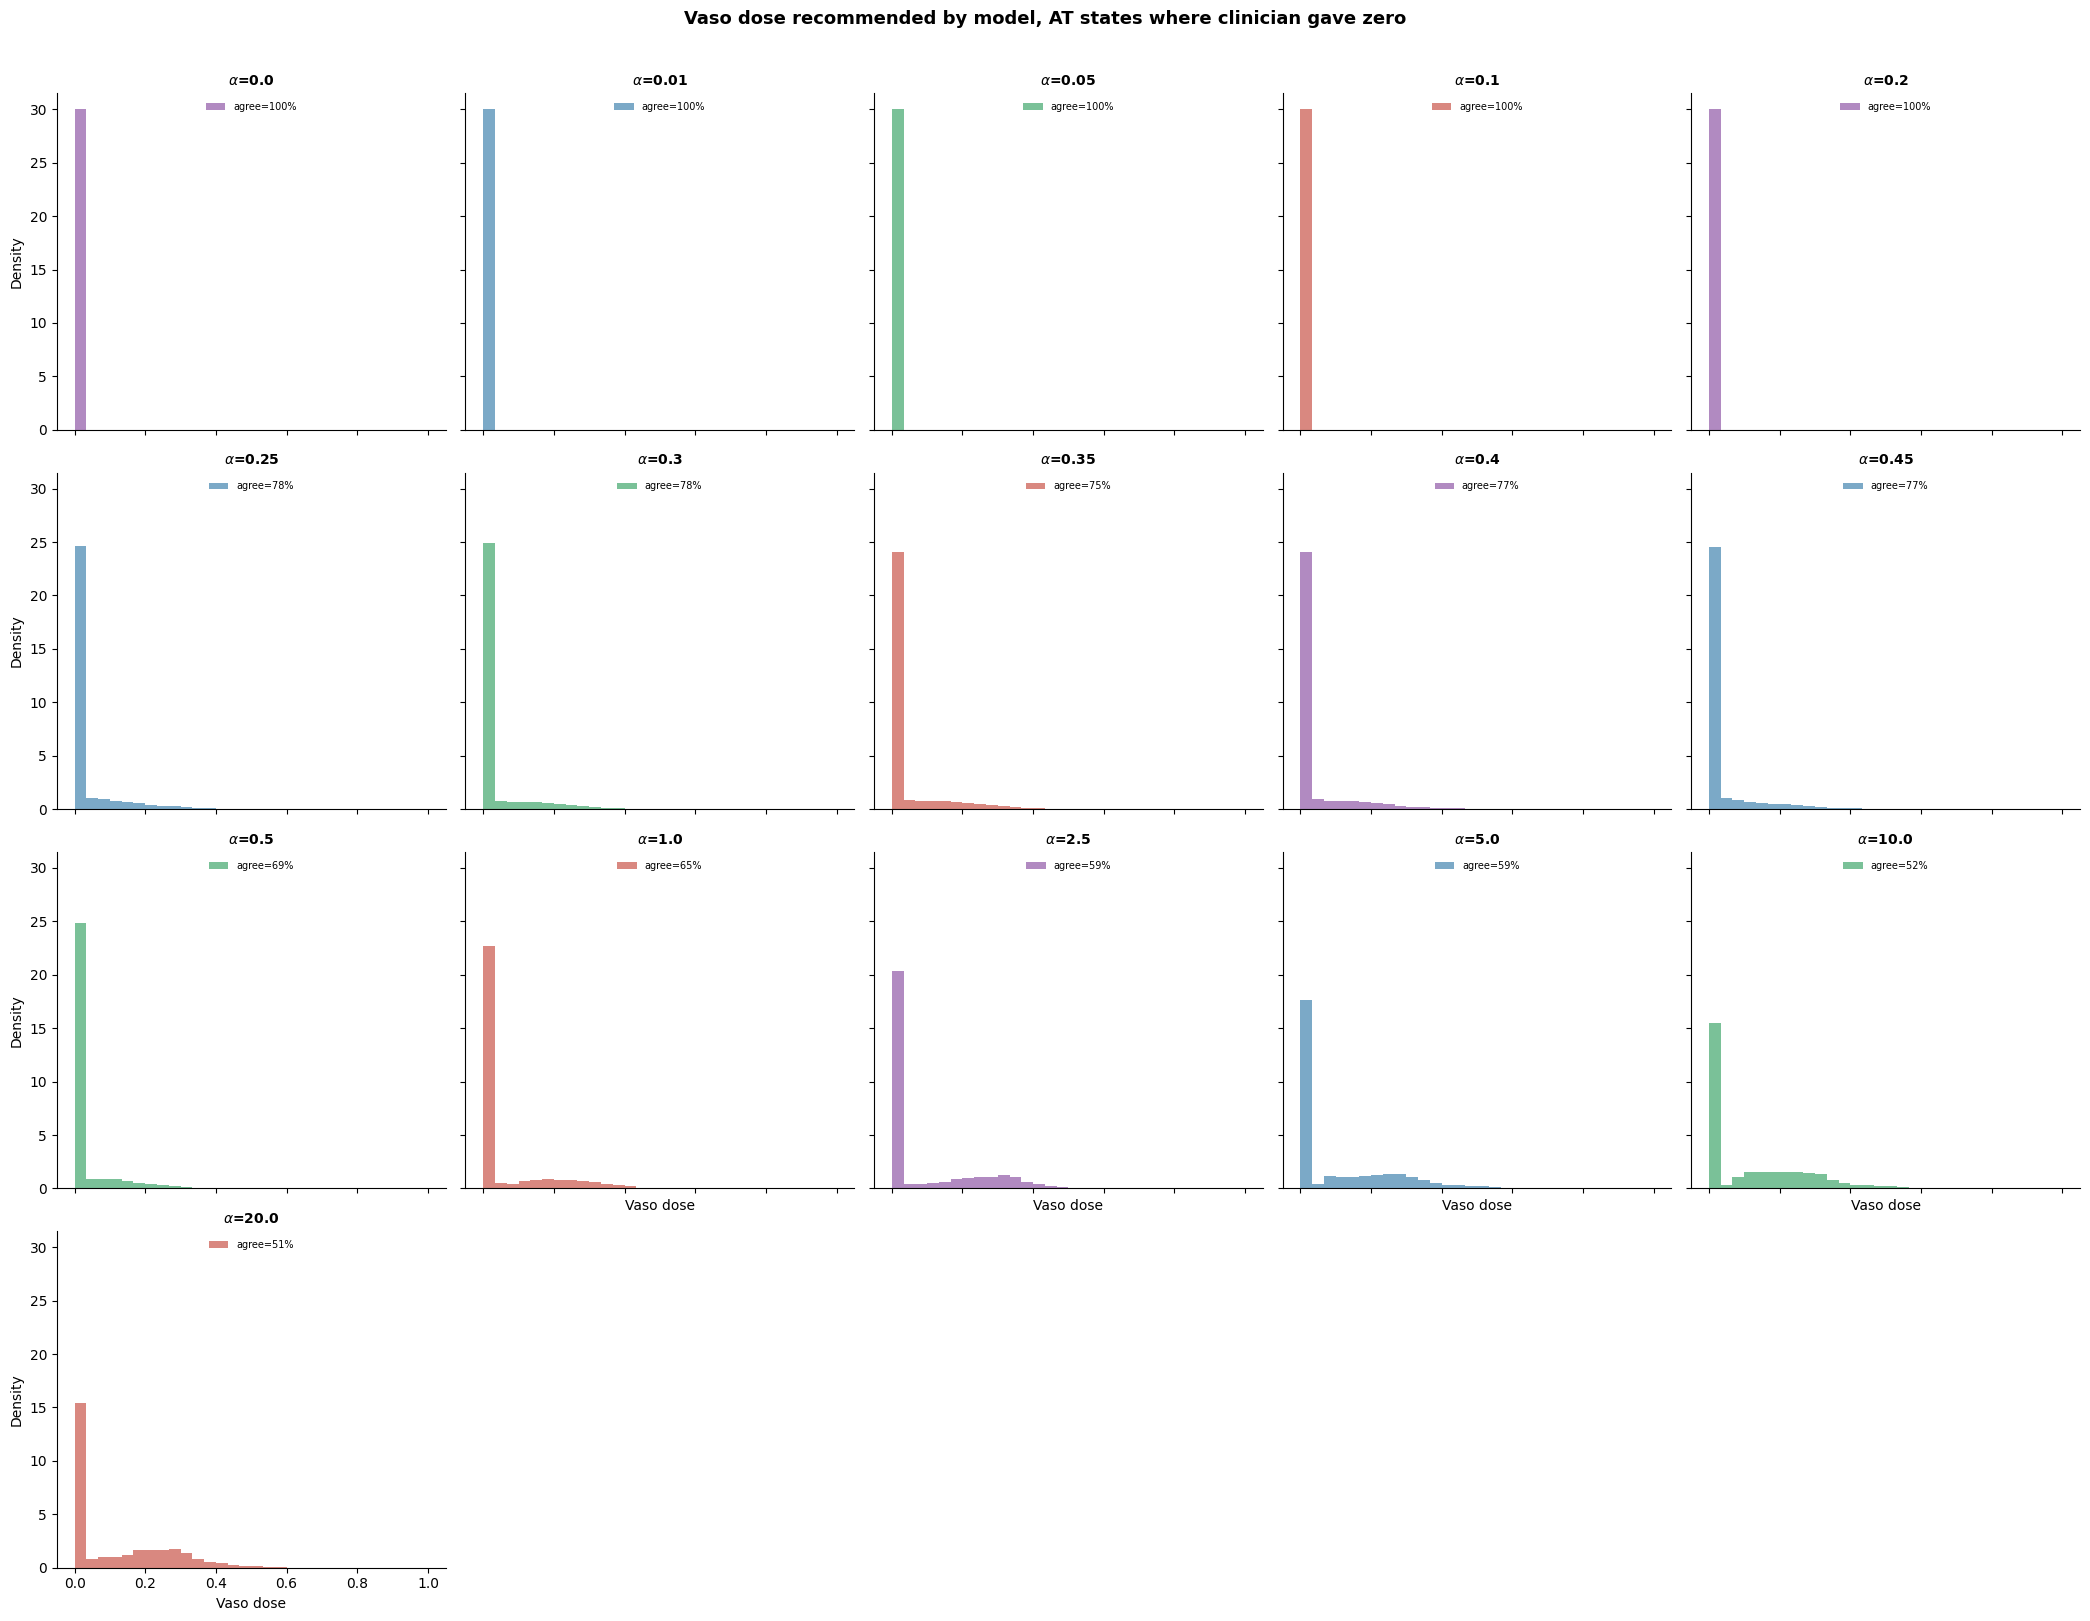

In [54]:
fig = dose_hist.plot_dose_histograms_at_clinician_zero(
    first_seed_by_coef, processor=processors['val'], clinician_actions=clinician_actions_val,
    dim=1, dim_name="Vaso", get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(SAVE_DIR, "vaso_at_clinician_zero_by_coef.png"),
)

# Notes
- If there is one seed per coefficient, treat the tipping-point *location* as provisional (single-seed noise has been 5–10× in this project); retrain a few seeds at the coefficients bracketing `c*`.
- "Unit dose" is on the log1p/min-max normalised VIS scale.
- `c*` bounds the *combined* effect of confounding, any true harm, and CQL/architecture effects; sections 1–2 are what attribute it to confounding.